# Frag Gen Comparison

Compare three NIST23 d3 fragmentation generation configs:

| Config | `multi_cut_bfs` | `max_cut_size` | `smarts_prepass` | `min_frag_atoms` |
|--------|----------------|----------------|-----------------|------------------|
| **baseline** (`_isoFalse`) | False | — | — | — |
| **mbfs** (`_isoFalse_mbfs`) | True | 2 | False | 3 |
| **mbfs_prepass** (`_isoFalse_mbfs_prepass`) | True | 2 | True | — |

In [1]:
import io
import json
import pickle
import tarfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FRAG_DP = Path("../data/frag")

CONFIGS = {
    "baseline": FRAG_DP / "nist23_ma_mi_d3_h4_isoFalse",
    "mbfs": FRAG_DP / "nist23_ma_mi_d3_h4_isoFalse_mbfs.tar",
    "mbfs_prepass": FRAG_DP / "nist23_ma_mi_d3_h4_isoFalse_mbfs_prepass",
}

DF_NAMES = ["spec_stats_df", "mol_stats_df", "m_spec_stats_df", "m_mol_stats_df"]

In [2]:
def load_dfs(path: Path) -> dict[str, pd.DataFrame]:
    """Load all stats pkl files from a directory or a .tar archive."""
    dfs = {}
    if path.suffix == ".tar":
        with tarfile.open(path) as tf:
            members = {Path(m.name).name: m for m in tf.getmembers() if m.name.endswith(".pkl")}
            for name in DF_NAMES:
                fname = f"{name}.pkl"
                if fname in members:
                    f = tf.extractfile(members[fname])
                    dfs[name] = pd.read_pickle(io.BytesIO(f.read()))
        # also load global_stats.json from tar
        with tarfile.open(path) as tf:
            for m in tf.getmembers():
                if m.name.endswith("global_stats.json"):
                    f = tf.extractfile(m)
                    dfs["global_stats"] = json.load(f)
    else:
        for name in DF_NAMES:
            pkl_path = path / f"{name}.pkl"
            if pkl_path.exists():
                dfs[name] = pd.read_pickle(pkl_path)
        gs_path = path / "global_stats.json"
        if gs_path.exists():
            dfs["global_stats"] = json.loads(gs_path.read_text())
    return dfs


def _downcast_dfs(dfs: dict) -> dict:
    """Downcast float64 columns to float32 to halve memory usage."""
    for k, v in dfs.items():
        if isinstance(v, pd.DataFrame):
            f64_cols = v.select_dtypes(include="float64").columns
            dfs[k] = v.astype({c: "float32" for c in f64_cols})
    return dfs


all_dfs = {name: _downcast_dfs(load_dfs(path)) for name, path in CONFIGS.items()}

for cfg, dfs in all_dfs.items():
    print(f"{cfg}: loaded {list(dfs.keys())}")
    for k, v in dfs.items():
        if isinstance(v, pd.DataFrame):
            print(f"  {k}: {v.shape}")

FileNotFoundError: [Errno 2] No such file or directory: '../data/frag/nist23_ma_mi_d3_h4_isoFalse_mbfs.tar'

## Global Stats

In [ ]:
GS_KEYS = [
    "total_num_failures",
    "total_num_formulae",
    "dag_num_nodes/mean",
    "dag_num_nodes/50%",
    "dag_num_edges/mean",
    "dag_num_edges/50%",
    "num_formulae/mean",
    "num_formulae/50%",
    "formula_redundancy/mean",
    "formula_redundancy/50%",
    "spec/recall_0.01_h2/mean",
    "spec/wrecall_0.01_h2/mean",
    "spec/wrecall_0.01_h2/50%",
    "spec/prec_0.01_h2/mean",
    "spec/recall_0.01_h2/50%",
]

rows = []
for cfg, dfs in all_dfs.items():
    gs = dfs.get("global_stats", {})
    row = {"config": cfg}
    for k in GS_KEYS:
        row[k] = gs.get(k, float("nan"))
    rows.append(row)

gs_df = pd.DataFrame(rows).set_index("config").T
gs_df

config,baseline,mbfs,mbfs_prepass
total_num_failures,0,7,7
total_num_formulae,1162724,1531391,1628440
dag_num_nodes/mean,693.3267379186437,1386.318957771788,1676.0804248162738
dag_num_nodes/50%,304.0,387.0,413.0
dag_num_edges/mean,3750.418897129958,3359.2730204805675,4665.819614347916
dag_num_edges/50%,1226.0,874.0,946.0
num_formulae/mean,823.0022573363431,1182.0555209989172,1266.2317828921603
num_formulae/50%,549.0,651.0,676.0
formula_redundancy/mean,4.377786780409257,5.437873433522641,5.781945949389275
formula_redundancy/50%,3.4173506123851967,3.562618595825427,3.6504504504504505


## Spec-level Stats: recall & wrecall at 0.01 Da, h1–h4

In [ ]:
# Focus on standard tolerance 0.01 Da
TOL = "0.01"
H_LEVELS = [1, 2, 3, 4]
METRICS = ["recall", "wrecall", "prec", "ppt_peak", "ppt_formula"]

summary_rows = []
for cfg, dfs in all_dfs.items():
    spec_df = dfs.get("spec_stats_df")
    if spec_df is None:
        continue
    row = {"config": cfg}
    for h in H_LEVELS:
        for metric in METRICS:
            col = f"{metric}_{TOL}_h{h}"
            if col in spec_df.columns:
                row[f"{metric}_h{h}_mean"] = spec_df[col].mean()
                row[f"{metric}_h{h}_median"] = spec_df[col].median()
    # DAG stats
    for col in ["num_formulae", "dag_num_nodes", "dag_num_edges", "formula_redundancy"]:
        if col in spec_df.columns:
            row[f"{col}_mean"] = spec_df[col].mean()
            row[f"{col}_median"] = spec_df[col].median()
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index("config")

# Show recall/wrecall
recall_cols = [c for c in summary_df.columns if c.startswith(("recall", "wrecall"))]
print("=== Recall & wrecall (mean) ===")
display(summary_df[[c for c in recall_cols if "mean" in c]].T)

print("\n=== DAG stats ===")
dag_cols = [c for c in summary_df.columns if any(c.startswith(x) for x in ["num_formulae", "dag_num_nodes", "dag_num_edges", "formula_redundancy"])]
display(summary_df[dag_cols].T)

=== Recall & wrecall (mean) ===


config,baseline,mbfs,mbfs_prepass
recall_h1_mean,0.322657,0.386330,0.404931
wrecall_h1_mean,0.431174,0.509982,0.526948
recall_h2_mean,0.626252,0.632785,0.649304
wrecall_h2_mean,0.779909,0.768713,0.781000
recall_h3_mean,0.716338,0.718051,0.733312
wrecall_h3_mean,0.843857,0.831612,0.842739
recall_h4_mean,0.757700,0.754529,0.768295
wrecall_h4_mean,0.871634,0.855747,0.866035



=== DAG stats ===


config,baseline,mbfs,mbfs_prepass
num_formulae_mean,898.363735,1312.125862,1409.347462
num_formulae_median,618.000000,763.000000,798.000000
dag_num_nodes_mean,779.030724,1544.571411,1863.179077
dag_num_nodes_median,341.000000,462.000000,493.000000
dag_num_edges_mean,4173.773723,3743.620361,5143.046387
dag_num_edges_median,1422.000000,1041.000000,1131.000000
formula_redundancy_mean,4.666786,5.710246,6.083446
formula_redundancy_median,3.527304,3.732425,3.826813


## Distribution plots: wrecall & recall at 0.01 Da, h2

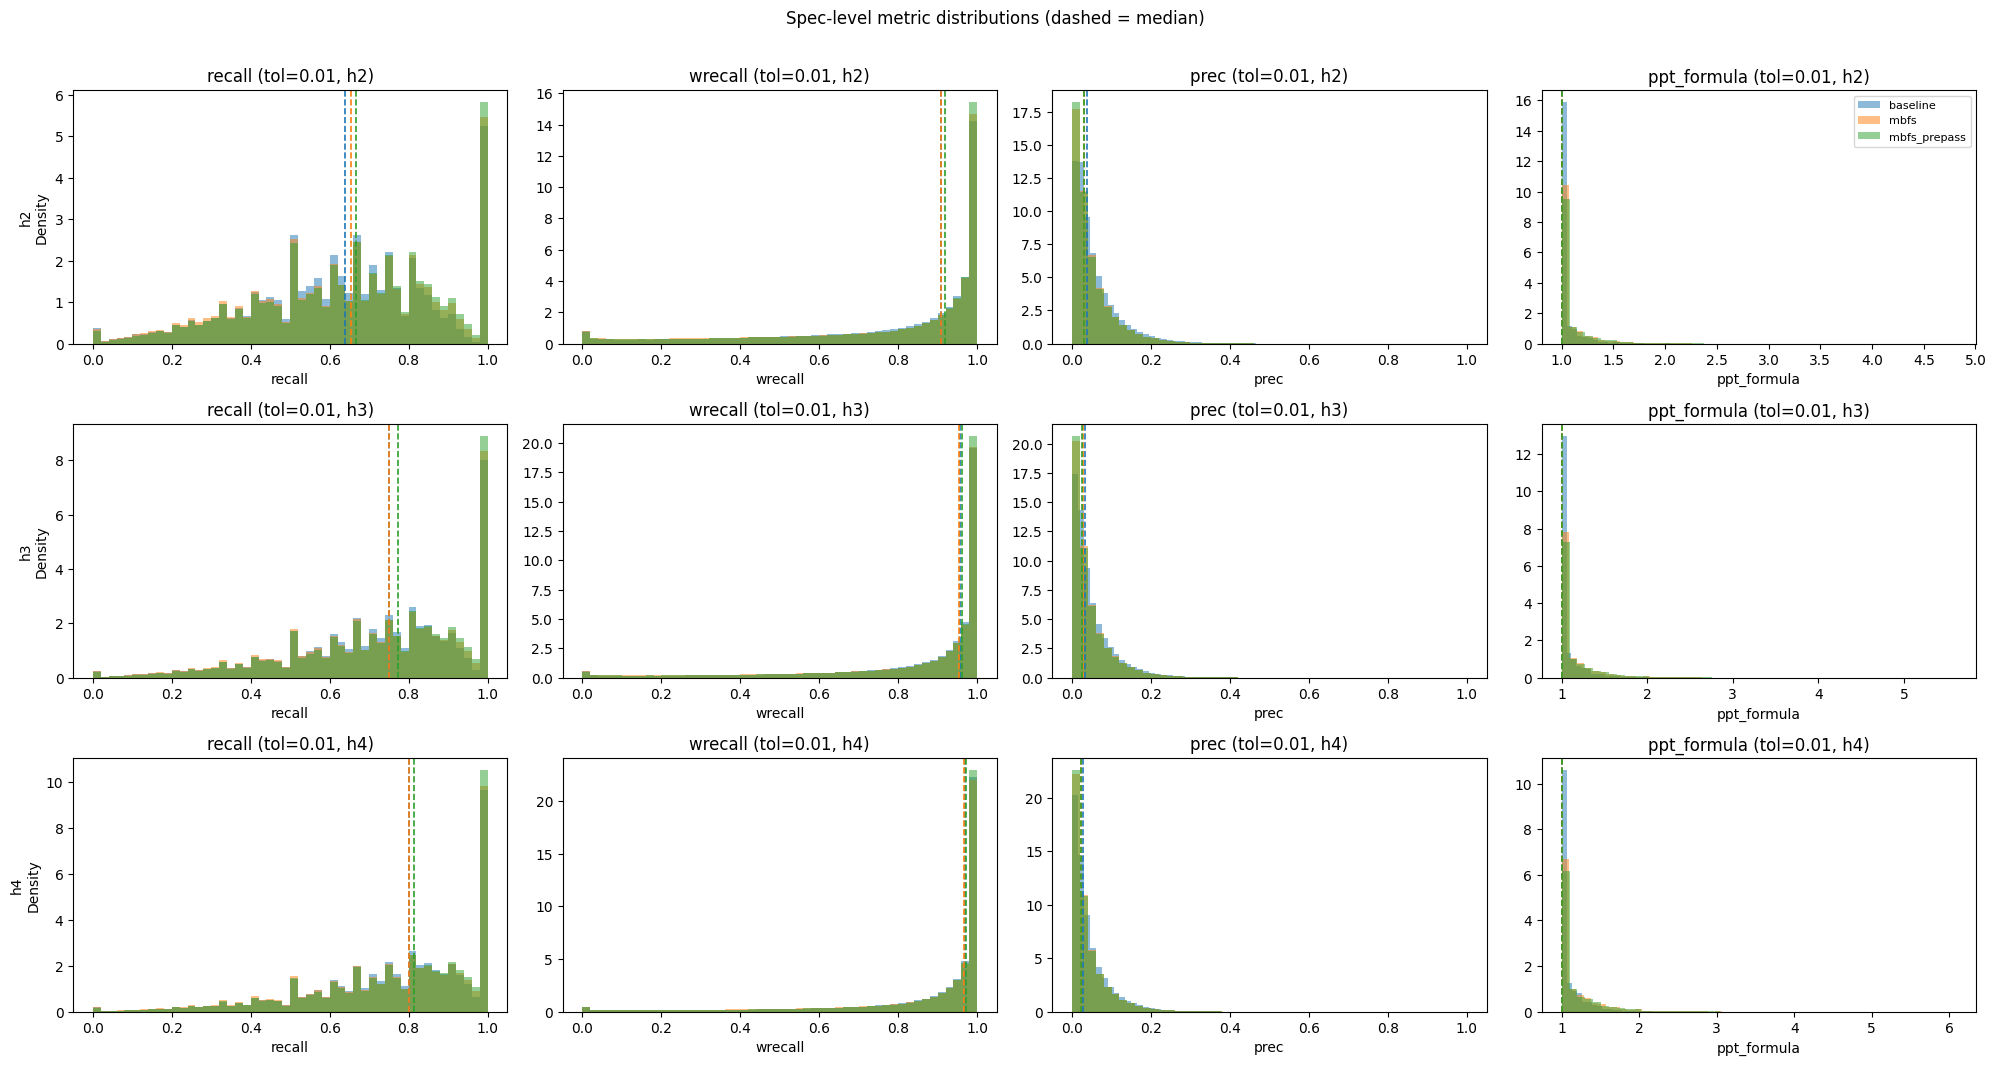

In [ ]:
COLORS = {"baseline": "tab:blue", "mbfs": "tab:orange", "mbfs_prepass": "tab:green"}
H_PLOT = [2, 3, 4]
PLOT_METRICS = ["recall", "wrecall", "prec", "ppt_formula"]

rows, cols = len(H_PLOT), len(PLOT_METRICS)
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.5 * rows))

for row_idx, H in enumerate(H_PLOT):
    for col_idx, metric in enumerate(PLOT_METRICS):
        ax = axes[row_idx, col_idx]
        col = f"{metric}_{TOL}_h{H}"
        for cfg, dfs in all_dfs.items():
            spec_df = dfs.get("spec_stats_df")
            if spec_df is None or col not in spec_df.columns:
                continue
            vals = spec_df[col].dropna()
            ax.hist(vals, bins=50, alpha=0.5, label=cfg, color=COLORS[cfg], density=True)
            ax.axvline(vals.median(), linestyle="--", color=COLORS[cfg], linewidth=1.2)
        ax.set_title(f"{metric} (tol={TOL}, h{H})")
        ax.set_xlabel(metric)
        if col_idx == 0:
            ax.set_ylabel(f"h{H}\nDensity")
        if row_idx == 0 and col_idx == cols - 1:
            ax.legend(fontsize=8)

plt.suptitle("Spec-level metric distributions (dashed = median)", y=1.01)
plt.tight_layout()
plt.show()


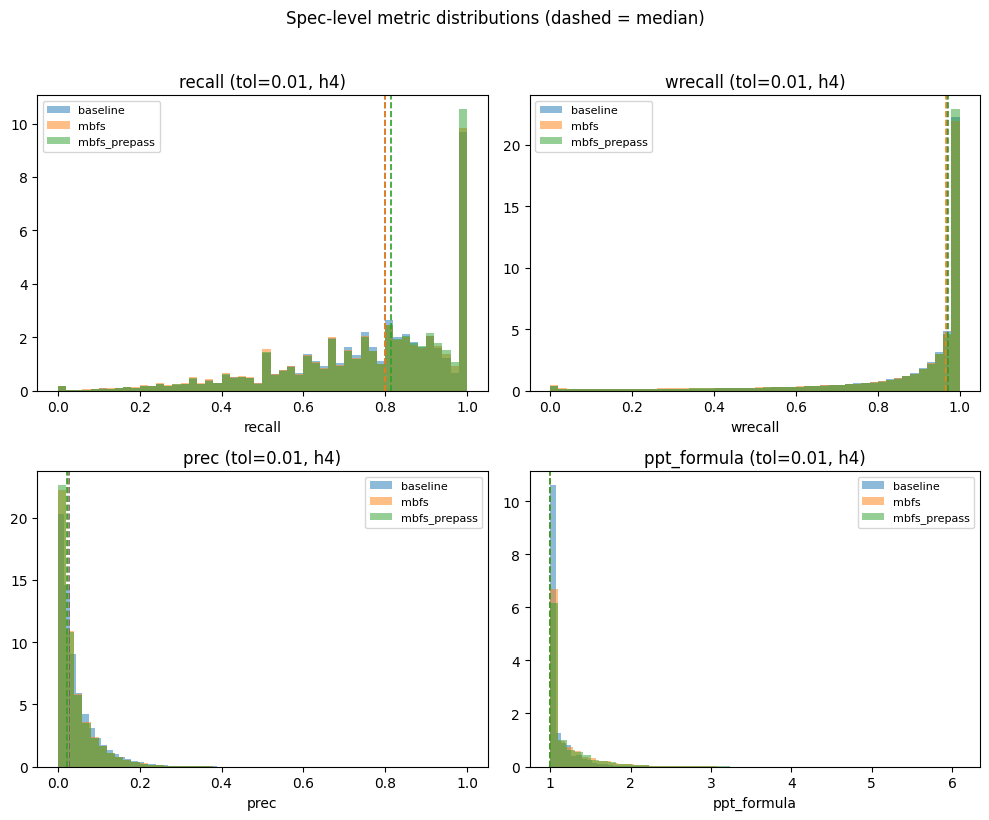

In [ ]:
# Duplicate distribution plots for H=4
COLORS = {"baseline": "tab:blue", "mbfs": "tab:orange", "mbfs_prepass": "tab:green"}
H = 4
PLOT_METRICS = ["recall", "wrecall", "prec", "ppt_formula"]

rows, cols = 2, 2
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
axes = axes.flatten()

for ax, metric in zip(axes, PLOT_METRICS):
    col = f"{metric}_{TOL}_h{H}"
    for cfg, dfs in all_dfs.items():
        spec_df = dfs.get("spec_stats_df")
        if spec_df is None or col not in spec_df.columns:
            continue
        vals = spec_df[col].dropna()
        ax.hist(vals, bins=50, alpha=0.5, label=cfg, color=COLORS[cfg], density=True)
        ax.axvline(vals.median(), linestyle="--", color=COLORS[cfg], linewidth=1.2)
    ax.set_title(f"{metric} (tol={TOL}, h{H})")
    ax.set_xlabel(metric)
    ax.legend(fontsize=8)

# Turn off any unused subplots
for ax in axes[len(PLOT_METRICS):]:
    ax.axis('off')

plt.suptitle("Spec-level metric distributions (dashed = median)", y=1.02)
plt.tight_layout()
plt.show()


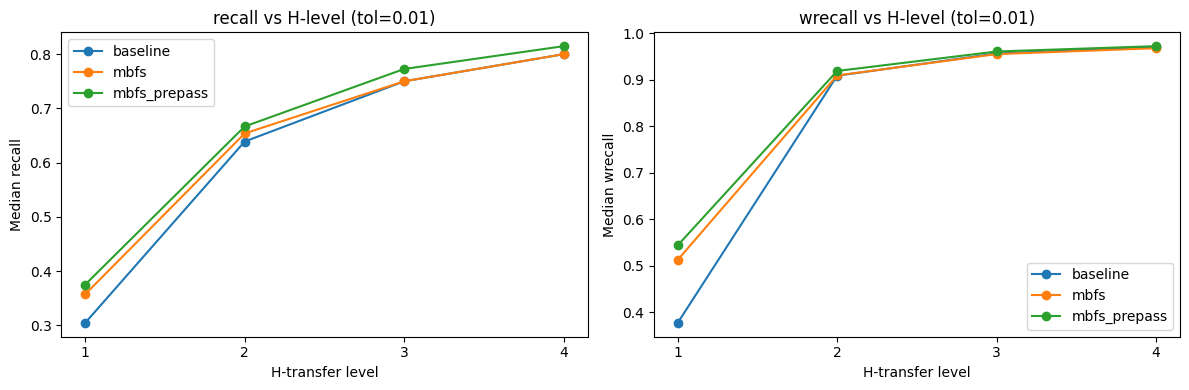

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ["recall", "wrecall"]):
    for cfg, dfs in all_dfs.items():
        spec_df = dfs.get("spec_stats_df")
        if spec_df is None:
            continue
        medians = []
        for h in H_LEVELS:
            col = f"{metric}_{TOL}_h{h}"
            if col in spec_df.columns:
                medians.append(spec_df[col].median())
            else:
                medians.append(np.nan)
        ax.plot(H_LEVELS, medians, marker="o", label=cfg, color=COLORS[cfg])
    ax.set_xlabel("H-transfer level")
    ax.set_ylabel(f"Median {metric}")
    ax.set_title(f"{metric} vs H-level (tol={TOL})")
    ax.legend()
    ax.set_xticks(H_LEVELS)

plt.tight_layout()
plt.show()

## num_formulae & dag_num_nodes distributions

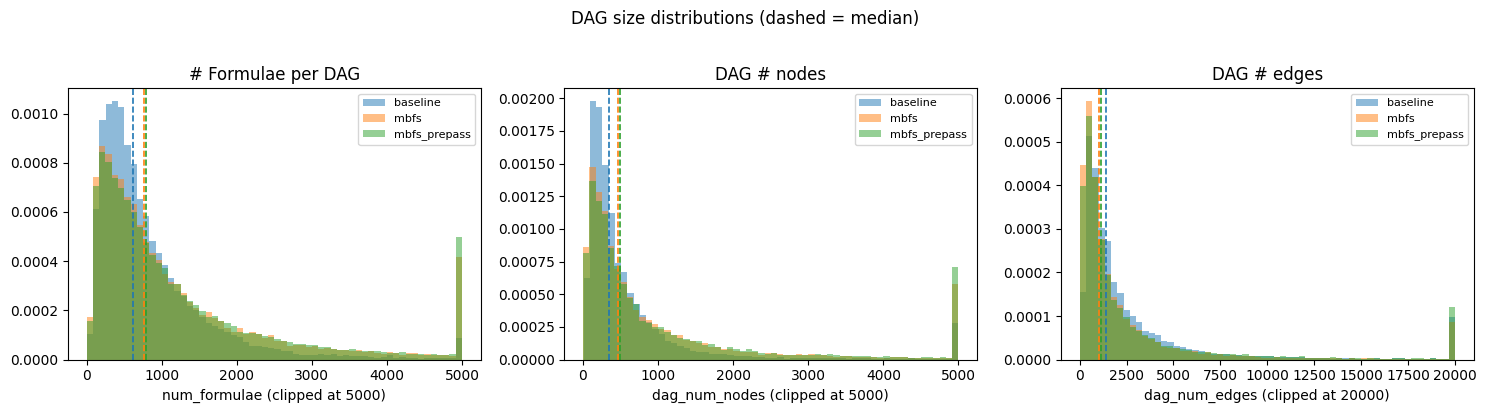

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, label, clip) in zip(
    axes,
    [
        ("num_formulae", "# Formulae per DAG", 5000),
        ("dag_num_nodes", "DAG # nodes", 5000),
        ("dag_num_edges", "DAG # edges", 20000),
    ],
):
    for cfg, dfs in all_dfs.items():
        spec_df = dfs.get("spec_stats_df")
        if spec_df is None or col not in spec_df.columns:
            continue
        vals = spec_df[col].clip(upper=clip).dropna()
        ax.hist(vals, bins=60, alpha=0.5, label=cfg, color=COLORS[cfg], density=True)
        ax.axvline(spec_df[col].median(), linestyle="--", color=COLORS[cfg], linewidth=1.2)
    ax.set_title(label)
    ax.set_xlabel(f"{col} (clipped at {clip})")
    ax.legend(fontsize=8)

plt.suptitle("DAG size distributions (dashed = median)", y=1.02)
plt.tight_layout()
plt.show()

## Mol-level: median wrecall & recall (m_mol_stats_df)

In [ ]:
mol_rows = []
for cfg, dfs in all_dfs.items():
    mol_df = dfs.get("m_mol_stats_df")
    if mol_df is None:
        mol_df = dfs.get("mol_stats_df")
    if mol_df is None:
        continue
    row = {"config": cfg, "n_mols": len(mol_df)}
    for h in H_LEVELS:
        for metric in ["recall", "wrecall", "prec"]:
            col = f"{metric}_{TOL}_h{h}"
            if col in mol_df.columns:
                row[f"{metric}_h{h}_median"] = mol_df[col].median()
                row[f"{metric}_h{h}_mean"] = mol_df[col].mean()
    mol_rows.append(row)

mol_summary = pd.DataFrame(mol_rows).set_index("config")
display(mol_summary.T)

config,baseline,mbfs,mbfs_prepass
n_mols,43414.000000,43407.000000,43407.000000
recall_h1_median,0.291133,0.354570,0.369767
recall_h1_mean,0.300311,0.364819,0.382161
wrecall_h1_median,0.333116,0.473906,0.497445
wrecall_h1_mean,0.378894,0.470580,0.487893
prec_h1_median,0.076577,0.064767,0.064488
prec_h1_mean,0.098019,0.088304,0.087854
recall_h2_median,0.618458,0.638514,0.654070
recall_h2_mean,0.609619,0.620821,0.634819
wrecall_h2_median,0.846706,0.838274,0.848604


## Direct diff: mbfs vs baseline & mbfs_prepass vs mbfs (spec-level, h2, 0.01 Da)

In [ ]:
# Join on spec_id to compare directly
H = 2
COMPARE_COLS = [f"{m}_{TOL}_h{H}" for m in ["recall", "wrecall", "prec", "ppt_formula"]]

baseline_df = all_dfs["baseline"]["spec_stats_df"].set_index("spec_id")[COMPARE_COLS]
mbfs_df = all_dfs["mbfs"]["spec_stats_df"].set_index("spec_id")[COMPARE_COLS]
prepass_df = all_dfs["mbfs_prepass"]["spec_stats_df"].set_index("spec_id")[COMPARE_COLS]

common_base_mbfs = baseline_df.index.intersection(mbfs_df.index)
common_mbfs_pp = mbfs_df.index.intersection(prepass_df.index)

diff_mbfs_vs_base = mbfs_df.loc[common_base_mbfs] - baseline_df.loc[common_base_mbfs]
diff_pp_vs_mbfs = prepass_df.loc[common_mbfs_pp] - mbfs_df.loc[common_mbfs_pp]

print(f"Specs in common (mbfs vs baseline): {len(common_base_mbfs)}")
print(f"Specs in common (prepass vs mbfs):   {len(common_mbfs_pp)}")

print("\n=== mbfs - baseline (mean delta) ===")
display(diff_mbfs_vs_base.mean().to_frame("mean_delta").T)

print("\n=== mbfs_prepass - mbfs (mean delta) ===")
display(diff_pp_vs_mbfs.mean().to_frame("mean_delta").T)

Specs in common (mbfs vs baseline): 804966
Specs in common (prepass vs mbfs):   804966

=== mbfs - baseline (mean delta) ===


,recall_0.01_h2,wrecall_0.01_h2,prec_0.01_h2,ppt_formula_0.01_h2
mean_delta,0.006548,-0.011194,-0.008047,0.038889



=== mbfs_prepass - mbfs (mean delta) ===


,recall_0.01_h2,wrecall_0.01_h2,prec_0.01_h2,ppt_formula_0.01_h2
mean_delta,0.016519,0.012288,-0.000724,0.007028


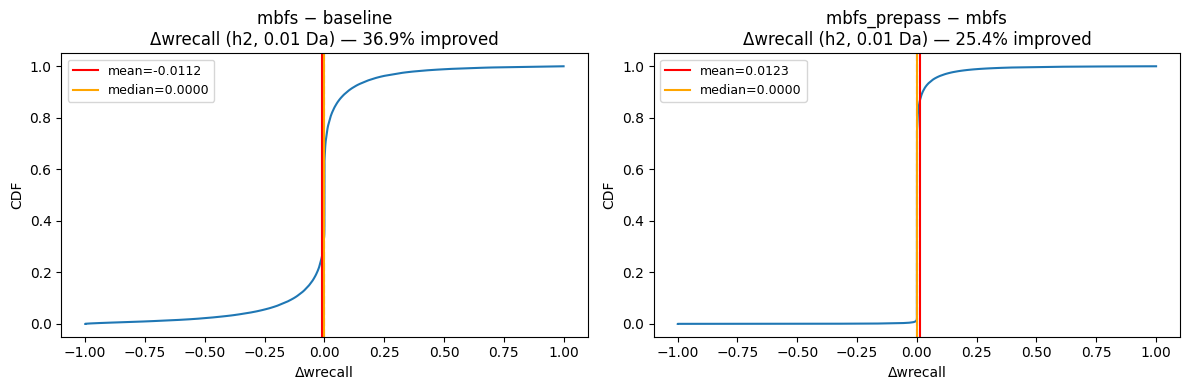

In [ ]:
# CDF of wrecall delta
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
wcol = f"wrecall_{TOL}_h{H}"

for ax, (diff, title) in zip(
    axes,
    [
        (diff_mbfs_vs_base[wcol], "mbfs − baseline"),
        (diff_pp_vs_mbfs[wcol], "mbfs_prepass − mbfs"),
    ],
):
    vals = diff.sort_values()
    cdf = np.arange(1, len(vals) + 1) / len(vals)
    ax.plot(vals, cdf)
    ax.axvline(0, color="gray", linestyle="--")
    ax.axvline(vals.mean(), color="red", linestyle="-", label=f"mean={vals.mean():.4f}")
    ax.axvline(vals.median(), color="orange", linestyle="-", label=f"median={vals.median():.4f}")
    frac_pos = (vals > 0).mean()
    ax.set_title(f"{title}\nΔwrecall (h{H}, {TOL} Da) — {frac_pos:.1%} improved")
    ax.set_xlabel("Δwrecall")
    ax.set_ylabel("CDF")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# spec_stats_df freed after low-wrecall analysis section (see end of that section)

## _org.tar vs baseline tar: are they the same?

`nist23_ma_mi_d3_h4_isoFalse_org.tar` (older run, 2.7 GB) vs `nist23_ma_mi_d3_h4_isoFalse.tar` (newer run, 2.8 GB).
Both are **baseline** single-cut BFS — not multi-cut. Checking whether DAG content differs.

In [ ]:
import bz2

ORG_TAR = FRAG_DP / "nist23_ma_mi_d3_h4_isoFalse_org.tar"
NEW_TAR = FRAG_DP / "nist23_ma_mi_d3_h4_isoFalse.tar"

org_tar = tarfile.open(ORG_TAR)
new_tar = tarfile.open(NEW_TAR)

org_dag_files = {
    int(m.name.split("/")[-1].replace(".pickle.bz2", "")): m
    for m in org_tar.getmembers()
    if m.name.endswith(".bz2")
}
new_dag_files = {
    int(m.name.split("/")[-1].replace(".pkl.bz2", "").lstrip("0") or "0"): m
    for m in new_tar.getmembers()
    if m.name.endswith(".bz2")
}

only_org = set(org_dag_files) - set(new_dag_files)
only_new = set(new_dag_files) - set(org_dag_files)
common = sorted(set(org_dag_files) & set(new_dag_files))

print(f"ORG mol count : {len(org_dag_files):,}")
print(f"NEW mol count : {len(new_dag_files):,}")
print(f"Common        : {len(common):,}")
print(f"Only in ORG   : {len(only_org)}")
print(f"Only in NEW   : {len(only_new)}")

# Pickle protocol check on first file of each
org_first = org_tar.extractfile(next(iter(org_dag_files.values())))
new_first = new_tar.extractfile(next(iter(new_dag_files.values())))
org_proto = bz2.decompress(org_first.read())[1]
new_proto = bz2.decompress(new_first.read())[1]
print(f"\nPickle protocol — ORG: {org_proto}, NEW: {new_proto}")

# File size stats from tar headers
org_sizes = [m.size for m in org_dag_files.values()]
new_sizes = [m.size for m in new_dag_files.values()]
print(f"\nCompressed file size (bz2):")
print(f"  ORG total: {sum(org_sizes)/1e9:.2f} GB  avg: {np.mean(org_sizes)/1e3:.1f} KB")
print(f"  NEW total: {sum(new_sizes)/1e9:.2f} GB  avg: {np.mean(new_sizes)/1e3:.1f} KB")

# Sample 200 molecules and compare DAG content
sample = common[:: max(1, len(common) // 200)][:200]
node_diffs, edge_diffs, form_diffs = [], [], []
for mol_id in sample:
    o = pickle.load(bz2.open(org_tar.extractfile(org_dag_files[mol_id])))
    n = pickle.load(bz2.open(new_tar.extractfile(new_dag_files[mol_id])))
    node_diffs.append(n["dag_num_nodes"] - o["dag_num_nodes"])
    edge_diffs.append(n["dag_num_edges"] - o["dag_num_edges"])
    form_diffs.append(len(n["idx_to_formula"]) - len(o["idx_to_formula"]))

n_changed = sum(1 for nd, ed, fd in zip(node_diffs, edge_diffs, form_diffs) if nd or ed or fd)
print(f"\nContent diff across {len(sample)} sampled molecules:")
print(f"  Molecules with any difference: {n_changed} / {len(sample)}")
print(f"  Δnodes    — mean={np.mean(node_diffs):+.2f}, min={min(node_diffs):+d}, max={max(node_diffs):+d}")
print(f"  Δedges    — mean={np.mean(edge_diffs):+.2f}, min={min(edge_diffs):+d}, max={max(edge_diffs):+d}")
print(f"  Δformulae — mean={np.mean(form_diffs):+.2f}, min={min(form_diffs):+d}, max={max(form_diffs):+d}")

ORG mol count : 43,414
NEW mol count : 43,414
Common        : 43,414
Only in ORG   : 0
Only in NEW   : 0

Pickle protocol — ORG: 4, NEW: 5

Compressed file size (bz2):
  ORG total: 1.42 GB  avg: 32.6 KB
  NEW total: 1.43 GB  avg: 33.0 KB

Content diff across 200 sampled molecules:
  Molecules with any difference: 0 / 200
  Δnodes    — mean=+0.00, min=+0, max=+0
  Δedges    — mean=+0.00, min=+0, max=+0
  Δformulae — mean=+0.00, min=+0, max=+0


## Low-wrecall spectra: quality analysis

Join frag stats with spec metadata to profile unexplainable spectra.

In [ ]:
# Load nist23 spec metadata
PROC_DP = Path("../data/proc/nist23")
spec_meta = pd.read_pickle(PROC_DP / "spec_df.pkl")[
    ["spec_id", "mol_id", "inst_type", "frag_mode", "prec_type",
     "ion_mode", "ace", "nce", "peaks"]
].copy()
spec_meta["num_peaks"] = spec_meta["peaks"].apply(
    lambda x: len(x) if x is not None else 0
)
print(f"spec_meta: {spec_meta.shape}")
spec_meta = spec_meta.drop(columns=["peaks"])  # free list column
print(spec_meta[["inst_type", "frag_mode"]].value_counts().head(10))


spec_meta: (1899597, 10)
inst_type  frag_mode
FT         HCD          1596801
           CID           189472
QTOF       CID            86743
Other      CID            16376
IT         CID             7016
QQQ        CID             2075
Other      HCD              784
QTOF       HCD              176
Name: count, dtype: int64


In [ ]:
# Join mbfs_prepass spec_stats with metadata — select only needed columns
W4 = "wrecall_0.01_h4"
W2 = "wrecall_0.01_h2"
pp_stats = all_dfs["mbfs_prepass"]["spec_stats_df"][["spec_id", W4, W2]].copy()
pp_stats["spec_id"] = pp_stats["spec_id"].astype(int)
merged = pp_stats.merge(spec_meta, on="spec_id", how="left")
print(f"merged: {merged.shape}  unmatched: {merged['inst_type'].isna().sum():,}")

# Quality tiers by wrecall_h4
merged["quality"] = pd.cut(
    merged[W4],
    bins=[-0.001, 0.1, 0.3, 0.5, 1.001],
    labels=["very_low (<0.1)", "low (0.1-0.3)", "medium (0.3-0.5)", "good (>0.5)"],
)
print("\nQuality tier counts:")
print(merged["quality"].value_counts().sort_index())


merged: (804966, 11)  unmatched: 0

Quality tier counts:
quality
very_low (<0.1)      16195
low (0.1-0.3)        23465
medium (0.3-0.5)     32137
good (>0.5)         733169
Name: count, dtype: int64


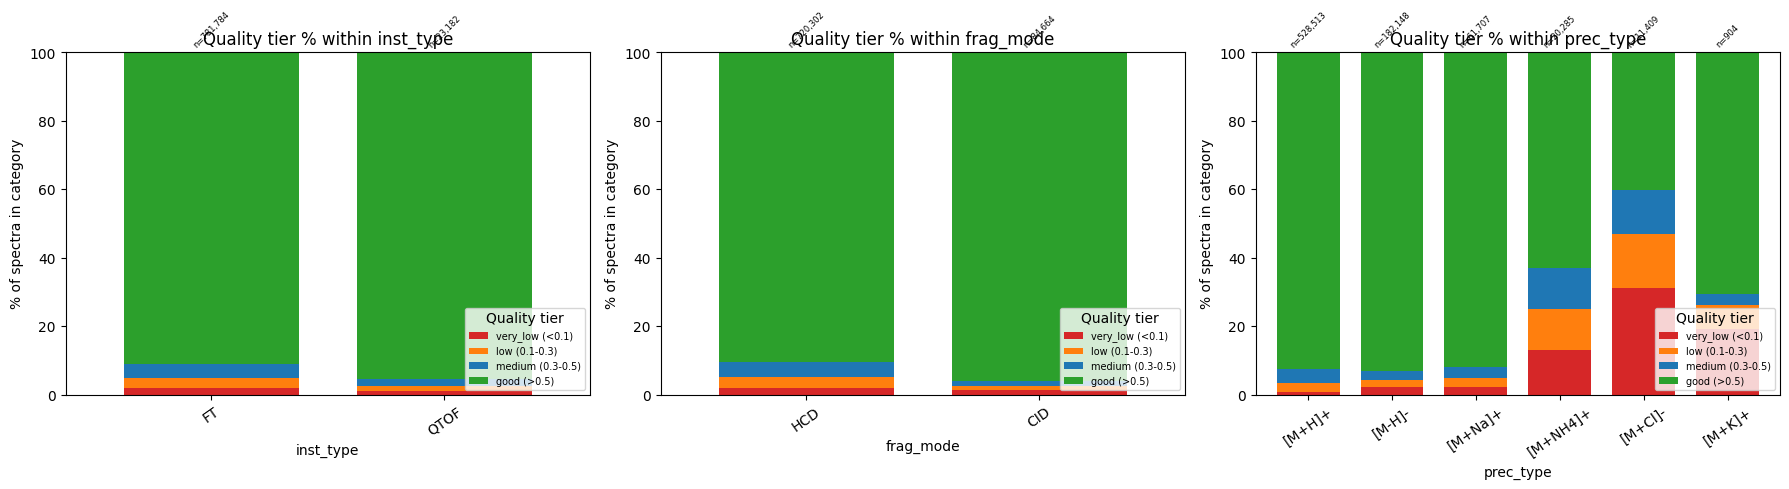

In [ ]:
# Instrument type, frag mode, prec_type breakdown by quality tier
# Each bar = one category value; stacked by quality tier (within-group %)
TIER_ORDER = ["very_low (<0.1)", "low (0.1-0.3)", "medium (0.3-0.5)", "good (>0.5)"]
TIER_COLORS = ["#d62728", "#ff7f0e", "#1f77b4", "#2ca02c"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ["inst_type", "frag_mode", "prec_type"]):
    tbl = (
        merged.groupby([col, "quality"], observed=True)
        .size()
        .unstack("quality", fill_value=0)
    )
    # Keep top-8 categories by total count
    top_cats = tbl.sum(axis=1).nlargest(8).index
    tbl = tbl.loc[top_cats]
    tbl_pct = tbl.div(tbl.sum(axis=1), axis=0) * 100
    # Reorder columns to tier order
    present_tiers = [t for t in TIER_ORDER if t in tbl_pct.columns]
    tbl_pct = tbl_pct[present_tiers]
    colors = [TIER_COLORS[TIER_ORDER.index(t)] for t in present_tiers]
    tbl_pct.plot(kind="bar", stacked=True, ax=ax, width=0.75, color=colors)
    ax.set_title(f"Quality tier % within {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("% of spectra in category")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=35)
    ax.legend(fontsize=7, loc="lower right", title="Quality tier")
    # Annotate total count per category
    for idx, (cat, row) in enumerate(tbl.iterrows()):
        ax.text(idx, 101, f"n={row.sum():,}", ha="center", va="bottom", fontsize=6, rotation=45)

plt.tight_layout()
plt.show()

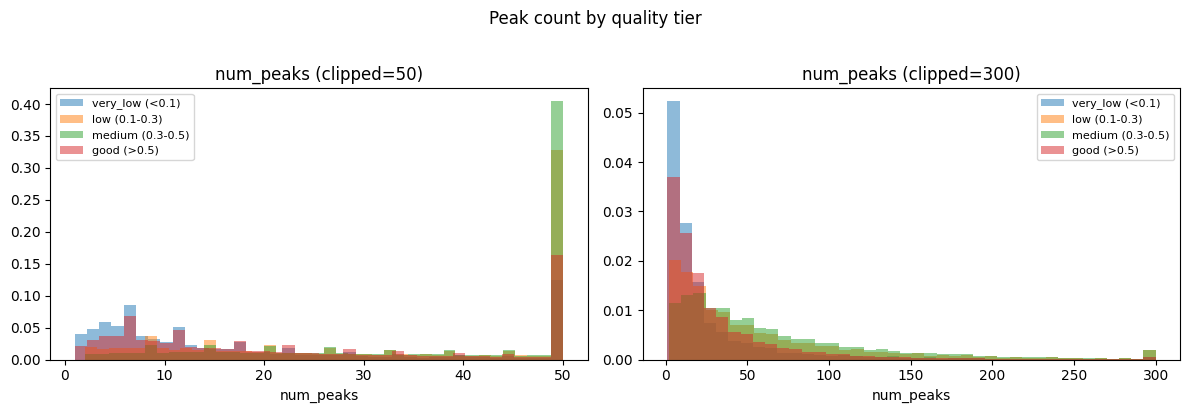

Median / mean num_peaks by quality tier:
                  median  mean
quality                       
very_low (<0.1)     12.0  27.9
low (0.1-0.3)       35.0  58.0
medium (0.3-0.5)    47.0  68.0
good (>0.5)         17.0  33.1


In [ ]:
# Peak count distribution by quality tier
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, clip in zip(axes, [50, 300]):
    for tier, grp in merged.groupby("quality", observed=True):
        vals = grp["num_peaks"].clip(upper=clip).dropna()
        ax.hist(vals, bins=40, alpha=0.5, label=tier, density=True)
    ax.set_title(f"num_peaks (clipped={clip})")
    ax.set_xlabel("num_peaks")
    ax.legend(fontsize=8)

plt.suptitle("Peak count by quality tier", y=1.02)
plt.tight_layout()
plt.show()

print("Median / mean num_peaks by quality tier:")
print(merged.groupby("quality", observed=True)["num_peaks"].agg(["median", "mean"]).round(1))


In [ ]:
# CE distribution: ACE for QTOF only, NCE for FT only
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

TIER_ORDER = ["very_low (<0.1)", "low (0.1-0.3)", "medium (0.3-0.5)", "good (>0.5)"]
TIER_COLORS = {
    "very_low (<0.1)": "tab:red",
    "low (0.1-0.3)": "tab:orange",
    "medium (0.3-0.5)": "tab:blue",
    "good (>0.5)": "tab:green",
}

CE_FILTERS = [
    (axes[0], "ace", merged["inst_type"] == "QTOF", 100, "ACE (QTOF only)"),
    (axes[1], "nce", merged["inst_type"] == "FT",   200, "NCE (FT only)"),
]

for ax, ce_col, mask, clip_val, title in CE_FILTERS:
    subset = merged[mask].copy()
    subset[ce_col] = subset[ce_col].clip(upper=clip_val)
    valid = subset[subset[ce_col].notna()]

    bins = np.linspace(0, clip_val, 41)
    bin_labels = 0.5 * (bins[:-1] + bins[1:])

    valid = valid.copy()
    valid["ce_bin"] = pd.cut(valid[ce_col], bins=bins, labels=bin_labels, include_lowest=True)
    counts = (
        valid.groupby(["ce_bin", "quality"], observed=True)
        .size()
        .unstack(fill_value=0)
        .reindex(columns=TIER_ORDER, fill_value=0)
    )
    pct = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100

    bottom = np.zeros(len(pct))
    for tier in TIER_ORDER:
        ax.bar(
            pct.index.astype(float),
            pct[tier].values,
            width=(bins[1] - bins[0]) * 0.9,
            bottom=bottom,
            color=TIER_COLORS[tier],
            label=tier,
        )
        bottom += pct[tier].fillna(0).values

    ax.set_title(f"{title} (clipped={clip_val})")
    ax.set_xlabel(ce_col.upper())
    ax.set_ylabel("% of spectra")
    ax.set_ylim(0, 100)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# Molecule-specific vs spectrum-specific: are all spectra of a mol bad?
mol_max_wrecall = merged.groupby("mol_id")[W4].max()
mol_min_wrecall = merged.groupby("mol_id")[W4].min()

n_all_bad = (mol_max_wrecall < 0.1).sum()   # ALL spectra bad → structure/DAG issue
n_some_bad = ((mol_min_wrecall < 0.1) & (mol_max_wrecall >= 0.1)).sum()  # SOME bad → noisy spec
n_total_mols = len(mol_max_wrecall)

print(f"Total molecules: {n_total_mols:,}")
print(f"Mols where ALL spectra have wrecall_h4 < 0.1 (DAG gap): {n_all_bad:,} ({n_all_bad/n_total_mols*100:.1f}%)")
print(f"Mols where SOME spectra have wrecall_h4 < 0.1 (noise):  {n_some_bad:,} ({n_some_bad/n_total_mols*100:.1f}%)")

# Spectra breakdown
very_low = merged[merged["quality"] == "very_low (<0.1)"]
print(f"\nVery-low spectra: {len(very_low):,} across {very_low['mol_id'].nunique():,} unique molecules")
print(f"avg very_low spectra/mol: {len(very_low) / very_low['mol_id'].nunique():.1f}")
print(f"avg all spectra/mol:      {len(merged) / n_total_mols:.1f}")


Total molecules: 43,407
Mols where ALL spectra have wrecall_h4 < 0.1 (DAG gap): 20 (0.0%)
Mols where SOME spectra have wrecall_h4 < 0.1 (noise):  4,583 (10.6%)

Very-low spectra: 16,195 across 4,603 unique molecules
avg very_low spectra/mol: 3.5
avg all spectra/mol:      18.5


In [ ]:
# Profile 'all-bad' molecules (max wrecall_h4 < 0.1 across all their spectra)
all_bad_mol_ids = mol_max_wrecall[mol_max_wrecall < 0.1].index
bad_mols_specs = merged[merged["mol_id"].isin(all_bad_mol_ids)]

print(f"Spectra from all-bad molecules: {len(bad_mols_specs):,}")
print("\ninst_type:")
print(bad_mols_specs["inst_type"].value_counts())
print("\nfrag_mode:")
print(bad_mols_specs["frag_mode"].value_counts())
print("\nprec_type (top 10):")
print(bad_mols_specs["prec_type"].value_counts().head(10))

print(f"\nMedian num_peaks: {bad_mols_specs['num_peaks'].median():.0f}")
print(f"Median wrecall_h2: {bad_mols_specs[W2].median():.4f}")
print(f"Median wrecall_h4: {bad_mols_specs[W4].median():.4f}")
print("(h2→h4 delta tells us if H-shifts help at all)")


Spectra from all-bad molecules: 55

inst_type:
inst_type
FT      40
QTOF    15
Name: count, dtype: int64

frag_mode:
frag_mode
HCD    32
CID    23
Name: count, dtype: int64

prec_type (top 10):
prec_type
[M+H]+      33
[M-H]-      17
[M+Na]+      4
[M+NH4]+     1
Name: count, dtype: int64

Median num_peaks: 6
Median wrecall_h2: 0.0056
Median wrecall_h4: 0.0093
(h2→h4 delta tells us if H-shifts help at all)


In [ ]:
# Free large spec_stats_dfs — no longer needed after low-wrecall analysis
for _cfg in list(all_dfs):
    all_dfs[_cfg].pop("spec_stats_df", None)
import gc; gc.collect()
print("spec_stats_df freed from all configs")

spec_stats_df freed from all configs
